In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()
print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()
filename = next(iter(uploaded))

df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)
display(df.head())

Saving movie_metadata_no_duplicates.csv to movie_metadata_no_duplicates (1).csv
Dataset loaded successfully!
Rows and columns: (4998, 28)


,color,director_name,num_critic_for_reviews,duration,director_facebook_likes,actor_3_facebook_likes,actor_2_name,actor_1_facebook_likes,gross,genres,...,num_user_for_reviews,language,country,content_rating,budget,title_year,actor_2_facebook_likes,imdb_score,aspect_ratio,movie_facebook_likes
0,Color,James Cameron,723.0,178.0,0.0,855.0,Joel David Moore,1000.0,760505847.0,Action|Adventure|Fantasy|Sci-Fi,...,3054.0,English,USA,PG-13,237000000.0,2009.0,936.0,7.9,1.78,33000
1,Color,Gore Verbinski,302.0,169.0,563.0,1000.0,Orlando Bloom,40000.0,309404152.0,Action|Adventure|Fantasy,...,1238.0,English,USA,PG-13,300000000.0,2007.0,5000.0,7.1,2.35,0
2,Color,Sam Mendes,602.0,148.0,0.0,161.0,Rory Kinnear,11000.0,200074175.0,Action|Adventure|Thriller,...,994.0,English,UK,PG-13,245000000.0,2015.0,393.0,6.8,2.35,85000
3,Color,Christopher Nolan,813.0,164.0,22000.0,23000.0,Christian Bale,27000.0,448130642.0,Action|Thriller,...,2701.0,English,USA,PG-13,250000000.0,2012.0,23000.0,8.5,2.35,164000
4,Color,Doug Walker,110.0,103.0,131.0,371.5,Rob Walker,131.0,25517500.0,Documentary,...,156.0,English,USA,R,20000000.0,2005.0,12.0,7.1,2.35,0


In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

Column names:
['color', 'director_name', 'num_critic_for_reviews', 'duration', 'director_facebook_likes', 'actor_3_facebook_likes', 'actor_2_name', 'actor_1_facebook_likes', 'gross', 'genres', 'actor_1_name', 'movie_title', 'num_voted_users', 'cast_total_facebook_likes', 'actor_3_name', 'facenumber_in_poster', 'plot_keywords', 'movie_imdb_link', 'num_user_for_reviews', 'language', 'country', 'content_rating', 'budget', 'title_year', 'actor_2_facebook_likes', 'imdb_score', 'aspect_ratio', 'movie_facebook_likes']

Data types:
color                         object
director_name                 object
num_critic_for_reviews       float64
duration                     float64
director_facebook_likes      float64
actor_3_facebook_likes       float64
actor_2_name                  object
actor_1_facebook_likes       float64
gross                        float64
genres                        object
actor_1_name                  object
movie_title                   object
num_voted_users           

In [4]:
print("Missing values in each column:")
display(
    df.isnull().sum()
    .sort_values(ascending=False)
    .to_frame("Missing Values")
)

print("Total duplicate rows:", df.duplicated().sum())

numeric_df = df.select_dtypes(include="number")
zero_counts = (numeric_df == 0).sum()

print("\nZero values in numeric columns:")
display(
    zero_counts[zero_counts > 0]
    .sort_values(ascending=False)
    .to_frame("Zero Count")
)

Missing values in each column:


,Missing Values
color,0
director_name,0
num_critic_for_reviews,0
duration,0
director_facebook_likes,0
actor_3_facebook_likes,0
actor_2_name,0
actor_1_facebook_likes,0
gross,0
genres,0


Total duplicate rows: 0

Zero values in numeric columns:


,Zero Count
movie_facebook_likes,2162
facenumber_in_poster,2136
director_facebook_likes,897
actor_3_facebook_likes,89
actor_2_facebook_likes,55
cast_total_facebook_likes,33
actor_1_facebook_likes,26


In [5]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
num_critic_for_reviews,4998.0,1.395970e+02,1.209164e+02,1.00,50.00,110.00,193.00,8.130000e+02
duration,4998.0,1.072007e+02,2.521190e+01,7.00,93.00,103.00,118.00,5.110000e+02
director_facebook_likes,4998.0,6.754964e+02,2.793896e+03,0.00,7.00,49.00,189.00,2.300000e+04
actor_3_facebook_likes,4998.0,6.386658e+02,1.639613e+03,0.00,134.00,371.50,634.75,2.300000e+04
actor_1_facebook_likes,4998.0,6.549140e+03,1.505247e+04,0.00,613.00,986.00,11000.00,6.400000e+05
gross,4998.0,4.433719e+07,6.234076e+07,162.00,8382841.25,25517500.00,51376923.25,7.605058e+08
num_voted_users,4998.0,8.347020e+04,1.380866e+05,5.00,8560.00,34260.50,96120.75,1.689764e+06
cast_total_facebook_likes,4998.0,9.676941e+03,1.816540e+04,0.00,1405.50,3085.50,13740.50,6.567300e+05
facenumber_in_poster,4998.0,1.367947e+00,2.012088e+00,0.00,0.00,1.00,2.00,4.300000e+01
num_user_for_reviews,4998.0,2.715272e+02,3.770563e+02,1.00,65.00,156.00,323.00,5.060000e+03


In [6]:
categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns

for col in categorical_cols[:10]:
    print(f"\nTop values in {col}:")
    display(
        df[col].value_counts(dropna=False)
        .head(10)
        .to_frame("Count")
    )


Top values in color:


,Count
color,
Color,4791
Black and White,207



Top values in director_name:


,Count
director_name,
Steven Spielberg,129
Woody Allen,22
Martin Scorsese,20
Clint Eastwood,20
Ridley Scott,17
Tim Burton,16
Spike Lee,16
Steven Soderbergh,16
Renny Harlin,15



Top values in actor_2_name:


...

,Count
plot_keywords,
based on novel,156
alien friendship|alien invasion|australia|flying car|mother daughter relationship,3
one word title,3
animal name in title|ape abducts a woman|gorilla|island|king kong,3
abuse|african american lesbian|lesbian|lesbian couple|school,2
dog|gambler|gambling|gangster|professor,2
adoption|baby|friend|pregnancy|school,2
anthology|child abuse|critically acclaimed|death|grindhouse,2
assistant|experiment|frankenstein|medical student|scientist,2



Top values in movie_imdb_link:


,Count
movie_imdb_link,
http://www.imdb.com/title/tt2224026/?ref_=fn_tt_tt_1,3
http://www.imdb.com/title/tt2638144/?ref_=fn_tt_tt_1,3
http://www.imdb.com/title/tt0360717/?ref_=fn_tt_tt_1,3
http://www.imdb.com/title/tt0232500/?ref_=fn_tt_tt_1,2
http://www.imdb.com/title/tt0092337/?ref_=fn_tt_tt_1,2
http://www.imdb.com/title/tt0056193/?ref_=fn_tt_tt_1,2
http://www.imdb.com/title/tt1401152/?ref_=fn_tt_tt_1,2
http://www.imdb.com/title/tt0970416/?ref_=fn_tt_tt_1,2
http://www.imdb.com/title/tt2058673/?ref_=fn_tt_tt_1,2



Top values in language:


,Count
language,
English,4676
French,73
Spanish,40
Hindi,28
Mandarin,24
German,19
Japanese,17
Cantonese,11
Italian,11


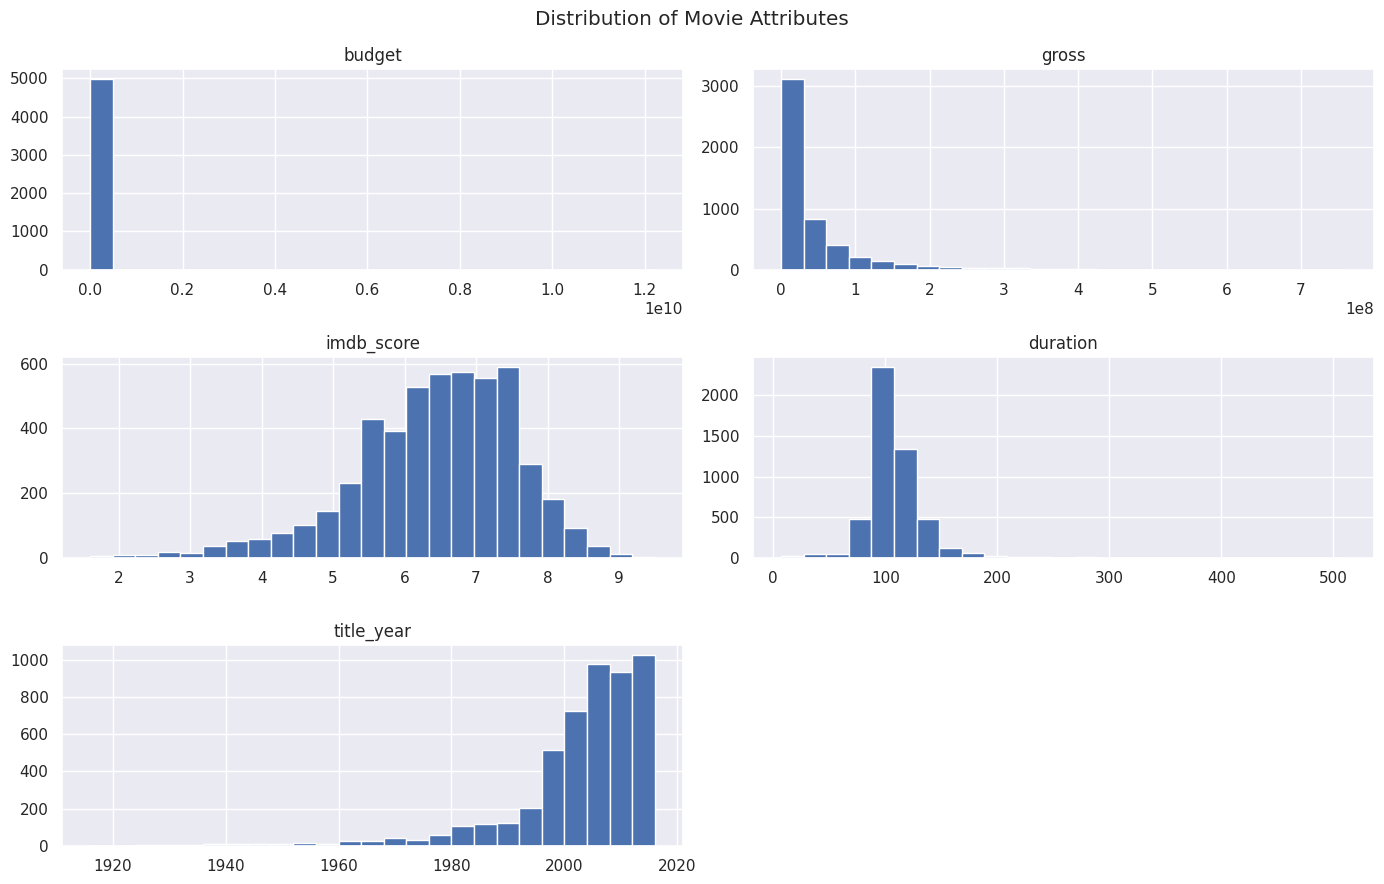

In [7]:
columns = [
    col for col in
    ["budget", "gross", "imdb_score", "duration", "title_year"]
    if col in df.columns
]

if columns:
    df[columns].hist(figsize=(14, 9), bins=25)
    plt.suptitle("Distribution of Movie Attributes")
    plt.tight_layout()
    plt.show()
else:
    print("Selected numerical columns were not found.")

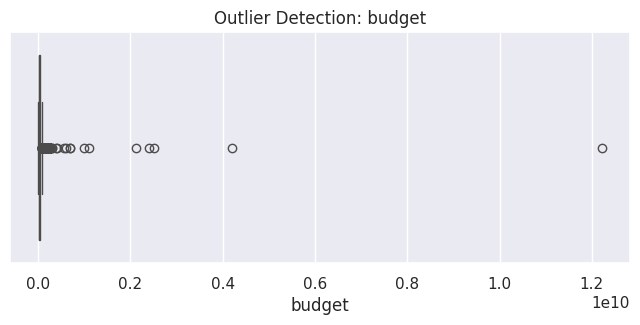

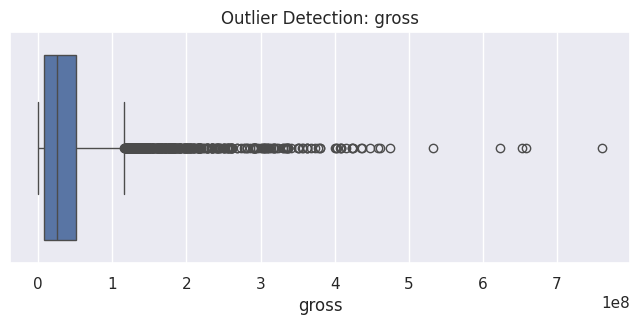

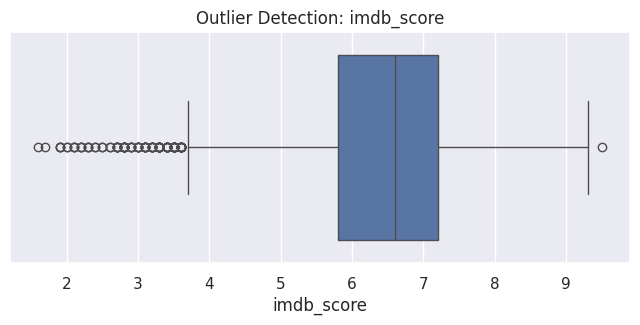

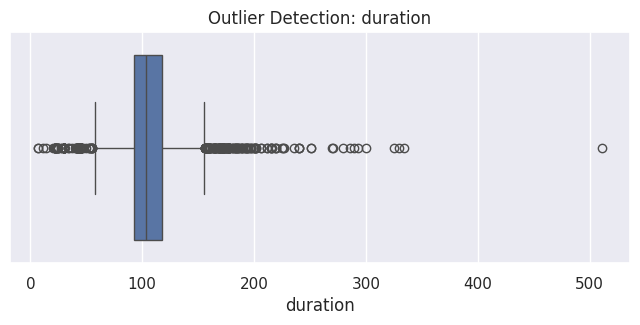

In [8]:
columns = [
    col for col in
    ["budget", "gross", "imdb_score", "duration"]
    if col in df.columns
]

for col in columns:
    values = pd.to_numeric(
        df[col], errors="coerce"
    ).dropna()

    plt.figure(figsize=(8, 3))
    sns.boxplot(x=values)
    plt.title(f"Outlier Detection: {col}")
    plt.xlabel(col)
    plt.show()

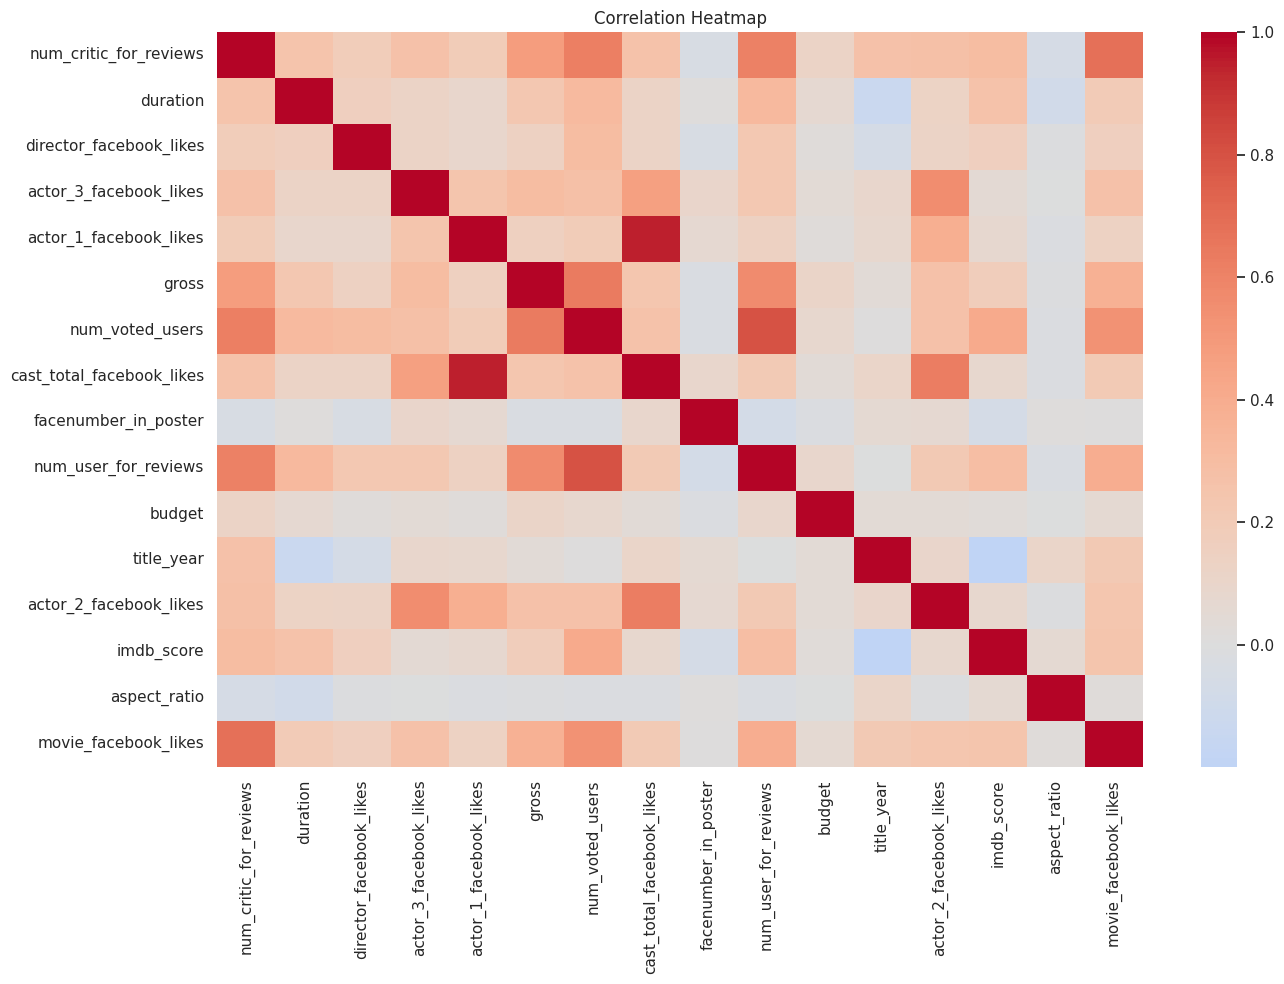

In [9]:
numeric_df = df.select_dtypes(include="number")

if numeric_df.shape[1] >= 2:
    correlation = numeric_df.corr()

    plt.figure(figsize=(14, 10))
    sns.heatmap(
        correlation,
        cmap="coolwarm",
        center=0
    )

    plt.title("Correlation Heatmap")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numerical columns.")

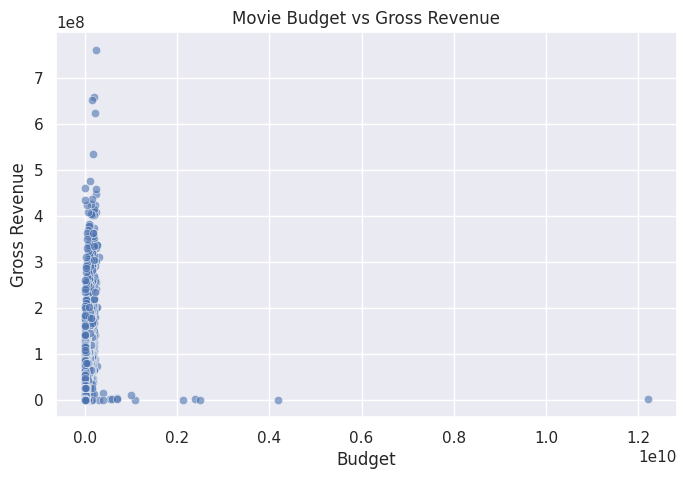

In [10]:
if "budget" in df.columns and "gross" in df.columns:
    plot_df = df[["budget", "gross"]].copy()

    plot_df["budget"] = pd.to_numeric(
        plot_df["budget"], errors="coerce"
    )
    plot_df["gross"] = pd.to_numeric(
        plot_df["gross"], errors="coerce"
    )

    plot_df = plot_df.dropna()
    plot_df = plot_df[
        (plot_df["budget"] > 0) &
        (plot_df["gross"] > 0)
    ]

    if not plot_df.empty:
        plt.figure(figsize=(8, 5))
        sns.scatterplot(
            data=plot_df,
            x="budget",
            y="gross",
            alpha=0.6
        )

        plt.title("Movie Budget vs Gross Revenue")
        plt.xlabel("Budget")
        plt.ylabel("Gross Revenue")
        plt.show()
    else:
        print("No valid positive budget and gross values found.")
else:
    print("Budget or gross column not found.")

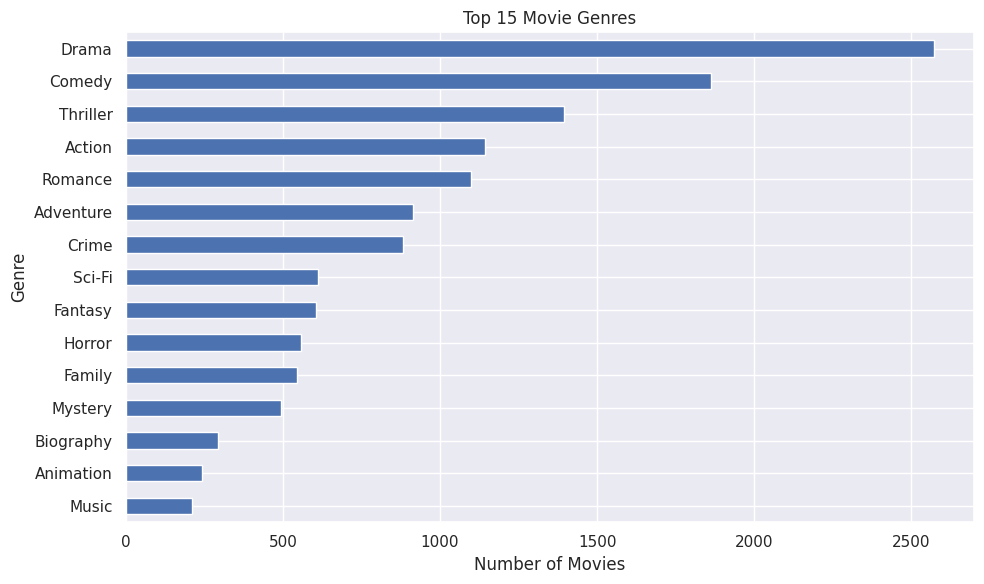

In [11]:
if "genres" in df.columns:
    genre_counts = (
        df["genres"]
        .dropna()
        .astype(str)
        .str.split("|")
        .explode()
        .str.strip()
        .value_counts()
        .head(15)
    )

    genre_counts.sort_values().plot(
        kind="barh",
        figsize=(10, 6)
    )

    plt.title("Top 15 Movie Genres")
    plt.xlabel("Number of Movies")
    plt.ylabel("Genre")
    plt.tight_layout()
    plt.show()
else:
    print("Genres column not found.")

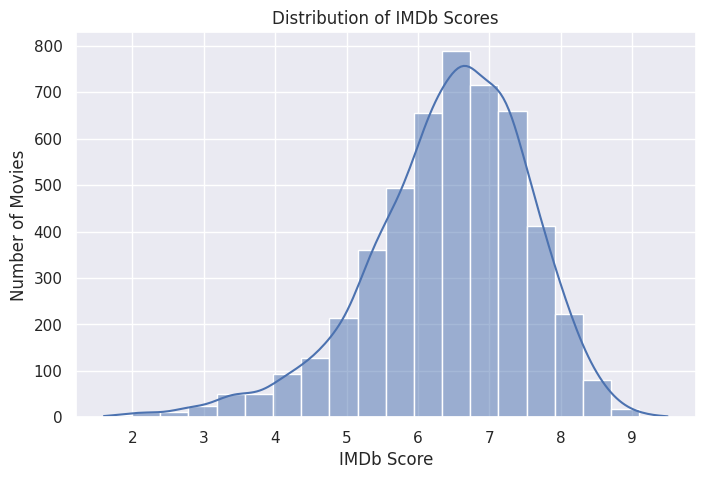

In [12]:
if "imdb_score" in df.columns:
    scores = pd.to_numeric(
        df["imdb_score"], errors="coerce"
    ).dropna()

    plt.figure(figsize=(8, 5))
    sns.histplot(scores, bins=20, kde=True)

    plt.title("Distribution of IMDb Scores")
    plt.xlabel("IMDb Score")
    plt.ylabel("Number of Movies")
    plt.show()
else:
    print("IMDb score column not found.")